In [31]:
# importing
# import libraries
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

# from sklearn.datasets import load_boston
# from fairlearn.datasets import fetch_boston

from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge

from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer, KNNImputer

import warnings
warnings.filterwarnings('ignore')

# Outlier 
## Global Outlier

In [6]:
# create dataset
np.random.seed(5)

X = np.random.uniform(155,165,100)
X = [round(i,2) for i in X]

y = [(2+0.35*i + np.take(np.random.normal(0,1.5,1),0)) for i in X]
y = [round(i,2) for i in y]

y_pred = [(2+0.35*i) for i in X]
y_pred = [round(i,2) for i in y_pred]

In [9]:
# convert to dataframe
df_assotiation = pd.DataFrame({
    'X':X,
    'y':y,
    'y_pred':y_pred}
)
df_assotiation.head()


,X,y,y_pred
0,157.22,59.76,57.03
1,163.71,58.66,59.30
2,157.07,55.23,56.97
3,164.19,57.37,59.47
4,159.88,59.27,57.96


Text(0, 0.5, 'Weight (kg)')

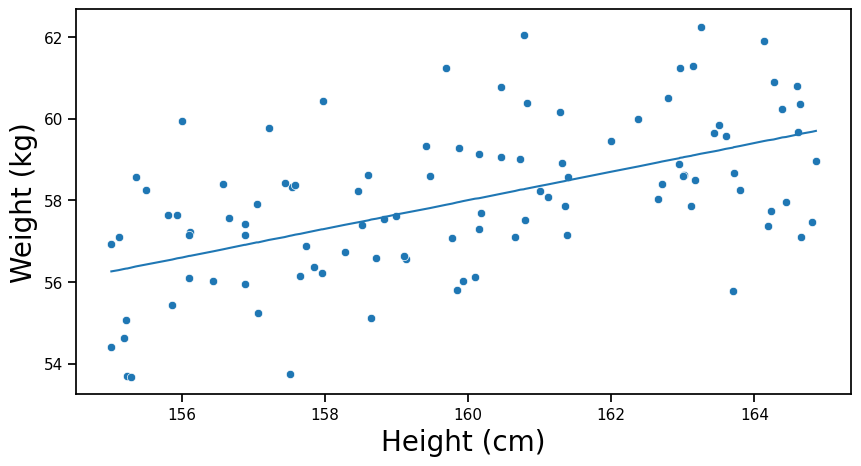

In [11]:
# make a plot
plt.figure(figsize=(10,5))
sns.set_context('notebook',font_scale=1)
sns.scatterplot(data=df_assotiation,x='X',y='y')
sns.lineplot(data=df_assotiation,x='X',y='y_pred')
plt.xlabel('Height (cm)', fontsize=20)
plt.ylabel('Weight (kg)', fontsize=20)

In [15]:
# making an outlier
X = [191,190]
y = [(2+0.35*i + np.take(np.random.normal(0,1.5,1),0)) for i in X]
y = [round(i,2) for i in y]
y_pred = [(2+0.35*i) for i in X]

# convert the outlier to dataframe
df_add = pd.DataFrame({
    'X':X,
    'y':y,
    'y_pred':y_pred
})

df_assotiation_outlier = df_assotiation.copy()
df_assotiation_outlier.loc[len(df_assotiation_outlier)] = df_add.loc[0]
df_assotiation_outlier.loc[len(df_assotiation_outlier)] = df_add.loc[1]
df_assotiation_outlier

,X,y,y_pred
0,157.22,59.76,57.03
1,163.71,58.66,59.30
2,157.07,55.23,56.97
3,164.19,57.37,59.47
4,159.88,59.27,57.96
...,...,...,...
97,155.20,54.64,56.32
98,160.73,59.00,58.26
99,159.11,56.63,57.69
100,191.00,70.68,68.85


Text(0, 0.5, 'Weight (kg)')

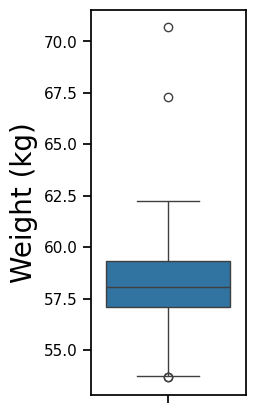

In [18]:
# check global outlier (weight)
plt.figure(figsize=(2,5))
sns.boxplot(data=df_assotiation_outlier,y='y')
plt.ylabel('Weight (kg)',fontsize=20)


Text(0, 0.5, 'Height (cm)')

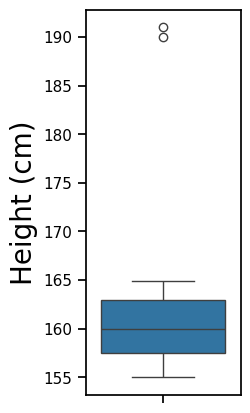

In [19]:
# check global outlier (height)
plt.figure(figsize=(2,5))
sns.boxplot(data=df_assotiation_outlier,y='X')
plt.ylabel('Height (cm)',fontsize=20)


## Contextual Outlier

In [23]:
X = [155,157]
y = [66,67]
y_pred = [(2+0.35*i) for i in X]
y_pred = [round(i,2) for i in y_pred]

df_add = pd.DataFrame({
    'X':X,
    'y':y,
    'y_pred':y_pred
})

df_assotiation_contextual = df_assotiation.copy()
df_assotiation_contextual.loc[len(df_assotiation_contextual)] = df_add.loc[0]
df_assotiation_contextual.loc[len(df_assotiation_contextual)] = df_add.loc[1]
df_assotiation_contextual

,X,y,y_pred
0,157.22,59.76,57.03
1,163.71,58.66,59.30
2,157.07,55.23,56.97
3,164.19,57.37,59.47
4,159.88,59.27,57.96
...,...,...,...
97,155.20,54.64,56.32
98,160.73,59.00,58.26
99,159.11,56.63,57.69
100,155.00,66.00,56.25


Text(0, 0.5, 'Weight (kg)')

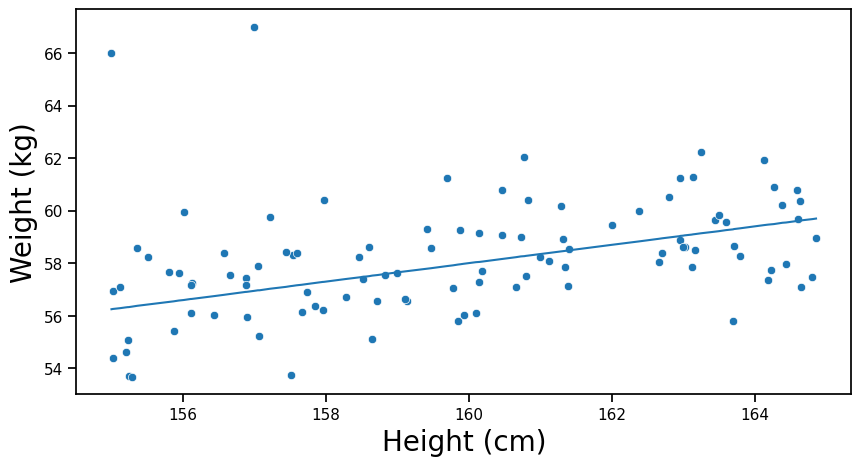

In [24]:
# make a plot
plt.figure(figsize=(10,5))
sns.set_context('notebook',font_scale=1)
sns.scatterplot(data=df_assotiation_contextual,x='X',y='y')
sns.lineplot(data=df_assotiation_contextual,x='X',y='y_pred')
plt.xlabel('Height (cm)', fontsize=20)
plt.ylabel('Weight (kg)', fontsize=20)

Text(0.5, 1.0, 'residual plot with outlier included')

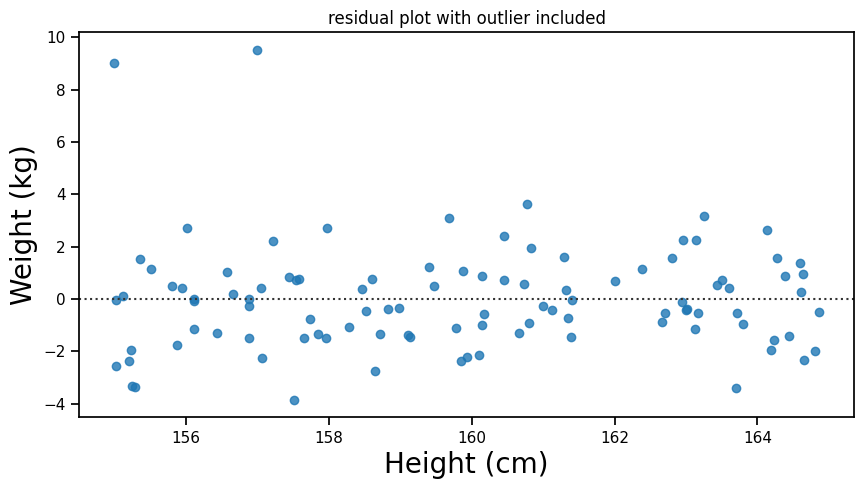

In [29]:
# residual plot
plt.figure(figsize=(10,5))
sns.set_context('notebook',font_scale=1)
sns.residplot(data=df_assotiation_contextual,x='X',y='y')
plt.xlabel('Height (cm)', fontsize=20)
plt.ylabel('Weight (kg)', fontsize=20)
plt.title('residual plot with outlier included')

Text(0.5, 1.0, 'residual plot with outlier excluded')

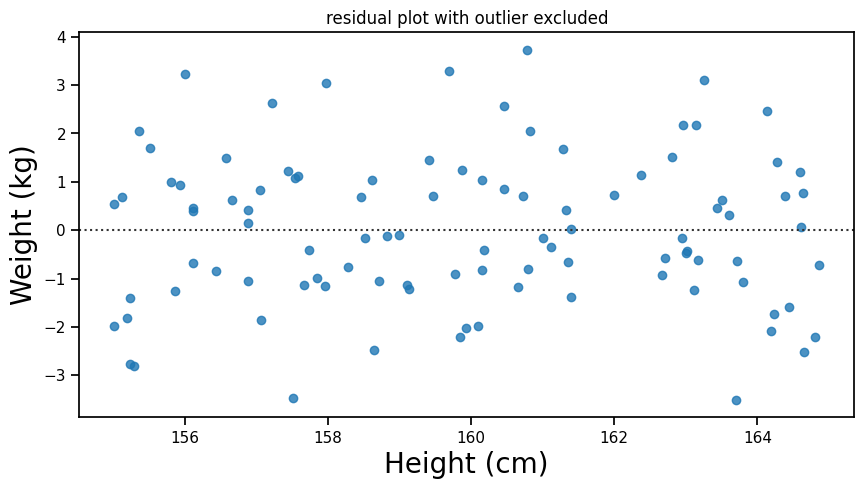

In [30]:
# residual plot
plt.figure(figsize=(10,5))
sns.set_context('notebook',font_scale=1)
sns.residplot(data=df_assotiation,x='X',y='y')
plt.xlabel('Height (cm)', fontsize=20)
plt.ylabel('Weight (kg)', fontsize=20)
plt.title('residual plot with outlier excluded')

# Missing Values Handling

In [32]:
# Simple Imputer for the missing values handling
# dataset again
df = pd.DataFrame(
    {'x1':[4,5,np.nan,6,7,9], # numerical
     'x2':[3,5,6,5,np.nan,5], # numerical
     'x3':[10,11,12,9,8,11], # numerical
     'x4':['A','A','C','C','D',np.nan], # cat_multiclass
     'x5':['X','Y','X','X',np.nan,'Y'], # cat_binary
     'x6':['M','M',np.nan,'M','N',np.nan] # cat_binary
    }
)
df

,x1,x2,x3,x4,x5,x6
0,4.0,3.0,10,A,X,M
1,5.0,5.0,11,A,Y,M
2,NaN,6.0,12,C,X,NaN
3,6.0,5.0,9,C,X,M
4,7.0,NaN,8,D,NaN,N
5,9.0,5.0,11,NaN,Y,NaN


In [35]:
# handling missing values: Numerical
imp_num = SimpleImputer(strategy='mean')
df[['x1','x2']] = imp_num.fit_transform(df[['x1','x2']])
df

,x1,x2,x3,x4,x5,x6
0,4.0,3.0,10.0,A,X,M
1,5.0,5.0,11.0,A,Y,M
2,6.2,6.0,12.0,C,X,NaN
3,6.0,5.0,9.0,C,X,M
4,7.0,4.8,8.0,D,NaN,N
5,9.0,5.0,11.0,NaN,Y,NaN


In [37]:
# handling missing values: categorical multiclass & binary
imp_mode = SimpleImputer(strategy='most_frequent')
df[['x4','x5']] = imp_mode.fit_transform(df[['x4','x5']])
df

,x1,x2,x3,x4,x5,x6
0,4.0,3.0,10.0,A,X,M
1,5.0,5.0,11.0,A,Y,M
2,6.2,6.0,12.0,C,X,NaN
3,6.0,5.0,9.0,C,X,M
4,7.0,4.8,8.0,D,X,N
5,9.0,5.0,11.0,A,Y,NaN


In [38]:
# handling missing values: binary
imp_const = SimpleImputer(strategy='constant',fill_value='P')
df[['x6']] = imp_const.fit_transform(df[['x6']])
df

,x1,x2,x3,x4,x5,x6
0,4.0,3.0,10.0,A,X,M
1,5.0,5.0,11.0,A,Y,M
2,6.2,6.0,12.0,C,X,P
3,6.0,5.0,9.0,C,X,M
4,7.0,4.8,8.0,D,X,N
5,9.0,5.0,11.0,A,Y,P


In [44]:
df_iter = pd.DataFrame(
    {'x1':[4,5,np.nan,6,7,9], # numerical
     'x2':[3,5,6,5,np.nan,5], # numerical
     'x3':[10,np.nan,12,9,8,11], # numerical
     'x4':['A','A','C','C','D','D'], # cat_multiclass
    }
)
df_iter

,x1,x2,x3,x4
0,4.0,3.0,10.0,A
1,5.0,5.0,NaN,A
2,NaN,6.0,12.0,C
3,6.0,5.0,9.0,C
4,7.0,NaN,8.0,D
5,9.0,5.0,11.0,D


In [45]:
# regressions fill / iterative imputer
imp_reg = IterativeImputer(max_iter=10, random_state=10)
df_iter[['x1','x2','x3']] = imp_reg.fit_transform(df_iter[['x1','x2','x3']])
df_iter

,x1,x2,x3,x4
0,4.000000,3.000000,10.000000,A
1,5.000000,5.000000,9.999585,A
2,6.208805,6.000000,12.000000,C
3,6.000000,5.000000,9.000000,C
4,7.000000,4.758154,8.000000,D
5,9.000000,5.000000,11.000000,D


In [46]:
#  reset the data
df_knn = pd.DataFrame(
    {'x1':[4,5,np.nan,6,7,9], # numerical
     'x2':[3,5,6,5,np.nan,5], # numerical
     'x3':[10,np.nan,12,9,8,11], # numerical
     'x4':['A','A','C','C','D','D'], # cat_multiclass
    }
)
df_knn

,x1,x2,x3,x4
0,4.0,3.0,10.0,A
1,5.0,5.0,NaN,A
2,NaN,6.0,12.0,C
3,6.0,5.0,9.0,C
4,7.0,NaN,8.0,D
5,9.0,5.0,11.0,D


In [48]:
# KNN fill
imp_knn = KNNImputer(n_neighbors=2,weights='uniform')
df_knn[['x1','x2','x3']] = imp_knn.fit_transform(df_knn[['x1','x2','x3']])
df_knn


,x1,x2,x3,x4
0,4.0,3.0,10.0,A
1,5.0,5.0,10.5,A
2,7.0,6.0,12.0,C
3,6.0,5.0,9.0,C
4,7.0,5.0,8.0,D
5,9.0,5.0,11.0,D
